### Domain Generalization (DG) Strategy

**Goal:** assess whether a random forest can predict the price class of listings in a city it has never seen during training.

#### 1. Building the Multi-Domain Dataset
* **Source Cities (Train):** Paris + Rome + Madrid (124,615 listings)
* **Target City (Test):** Vienna (10,115 listings)
* **Leave-one-city-out (LODO):** each of the four cities is then used once as the unseen target.

#### 2. Distribution Alignment
* The Q1–Q4 classes are defined on each city's own price distribution (data processing), so the task is to rank listings *within* their city.
* The 15 continuous features (size, distance, amenity scores, counts, neighbourhood share) are standardised with the mean and standard deviation of their own city (`standardize_per_city`). No label is used, so a new city can be standardised from its unlabelled listings.
* **Domain weighting:** each source city gets the same total weight during training.
* **Reranking:** the predicted classes of the target city are forced to the known 25% per class.

#### 3. Evaluation
* LODO F1-macro and accuracy, raw vs reranked predictions, with a McNemar test per city.
* Ablation: naive Paris-only model, pooled model, + domain weighting, + per-city standardisation, against an in-domain upper bound (cross-validation inside each city).
* Permutation importance per city: do the important variables stay the same across countries?

No need to re-run this — the dataframe is already built and ready to use.

Contributions : Félix bouvier

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, balanced_accuracy_score
from sklearn.utils import resample
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV
from statsmodels.stats.contingency_tables import mcnemar

FIG_DIR = Path("figures/2_generalisation")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

def save_fig(name, fig=None):
    """Save the current figure (or `fig`) as figures/2_generalisation/<name>.png."""
    (fig or plt.gcf()).savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

CITIES = ['Paris', 'Rome', 'Madrid', 'Vienna']
TARGET = 'target_class'
DROP = ['target_class', 'price_clean', 'city_label']
# Features whose scale depends on the city (counts, scores, distance, share of the city's listings in the neighbourhood)
CONT_COLS = ['accommodates', 'bedrooms', 'beds', 'minimum_nights_avg_ntm', 'number_of_reviews', 'dist_to_center',
             'bathrooms_qty', 'standing_thermal', 'score_chef_kitchen', 'score_coffee', 'score_wellness',
             'score_work', 'score_view', 'score_secure', 'neigh_popularity']

def standardize_per_city(df):
    """z-score of the continuous features with the mean and std of each listing's own city.
    No label is used, so a new city can be standardised from its (unlabelled) listings."""
    out = df.copy()
    grp = out.groupby('city_label')[CONT_COLS]
    out[CONT_COLS] = (out[CONT_COLS] - grp.transform('mean')) / grp.transform('std').replace(0, 1)
    return out

In [2]:
processed_files = {
    "paris": "data/paris_dataset_final_ready.csv.gz",
    "rome": "data/rome_dataset_final_ready.csv.gz",
    "madrid": "data/madrid_dataset_final_ready.csv.gz"
}

# 1. Load and concatenate the source cities
li = []
for city, path in processed_files.items():
    df = pd.read_csv(path, compression='gzip')
    li.append(df)

df_train_global = pd.concat(li, axis=0, ignore_index=True)
df_vienna = pd.read_csv("data/vienna_dataset_final_ready.csv.gz", compression='gzip')

# 2. Per-city standardisation of the continuous features (each city with its own mean and std)
df_train_std = standardize_per_city(df_train_global)
df_vienna_std = standardize_per_city(df_vienna)

print(f" Merged global dataset: {df_train_global.shape}")
print(f" Breakdown by city:\n{df_train_global['city_label'].value_counts()}")
print(f" Target city (Vienna): {df_vienna.shape}")

 Merged global dataset: (124615, 30)
 Breakdown by city:
city_label
Paris     73111
Rome      32902
Madrid    18602
Name: count, dtype: int64
 Target city (Vienna): (10115, 30)


### Domain shift diagnostics

Before modelling, we check how different the four cities are. Three sources of shift are visible in the data:
* **Price level**: the quartile boundaries differ a lot from one city to another, which is why the classes are defined per city.
* **Feature scales**: `neigh_popularity` is the share of the city's listings in the listing's neighbourhood, so its scale depends on how the city is divided (Inside Airbnb uses 20 arrondissements for Paris, 15 *municipi* for Rome, 23 *Bezirke* for Vienna and 128 *barrios* for Madrid). Counts such as `number_of_reviews` or `minimum_nights_avg_ntm` also follow local habits and regulation.
* **Time**: Paris was scraped on 2024-06-10, a few weeks before the Olympic Games, while the three other cities were scraped on 2025-09-14.

            listings  price_Q1  price_median  price_Q3  entire_home_share  neigh_popularity_median  reviews_median  min_nights_median
city_label                                                                                                                           
Paris          73111     110.0         164.0     284.0              0.914                    0.054             4.0                3.0
Rome           32902      94.0         133.0     193.0              0.780                    0.088            21.0                2.0
Madrid         18602      71.0         110.0     161.0              0.726                    0.016            18.0                3.0
Vienna         10115      66.0          93.0     139.0              0.886                    0.051            16.0                2.4


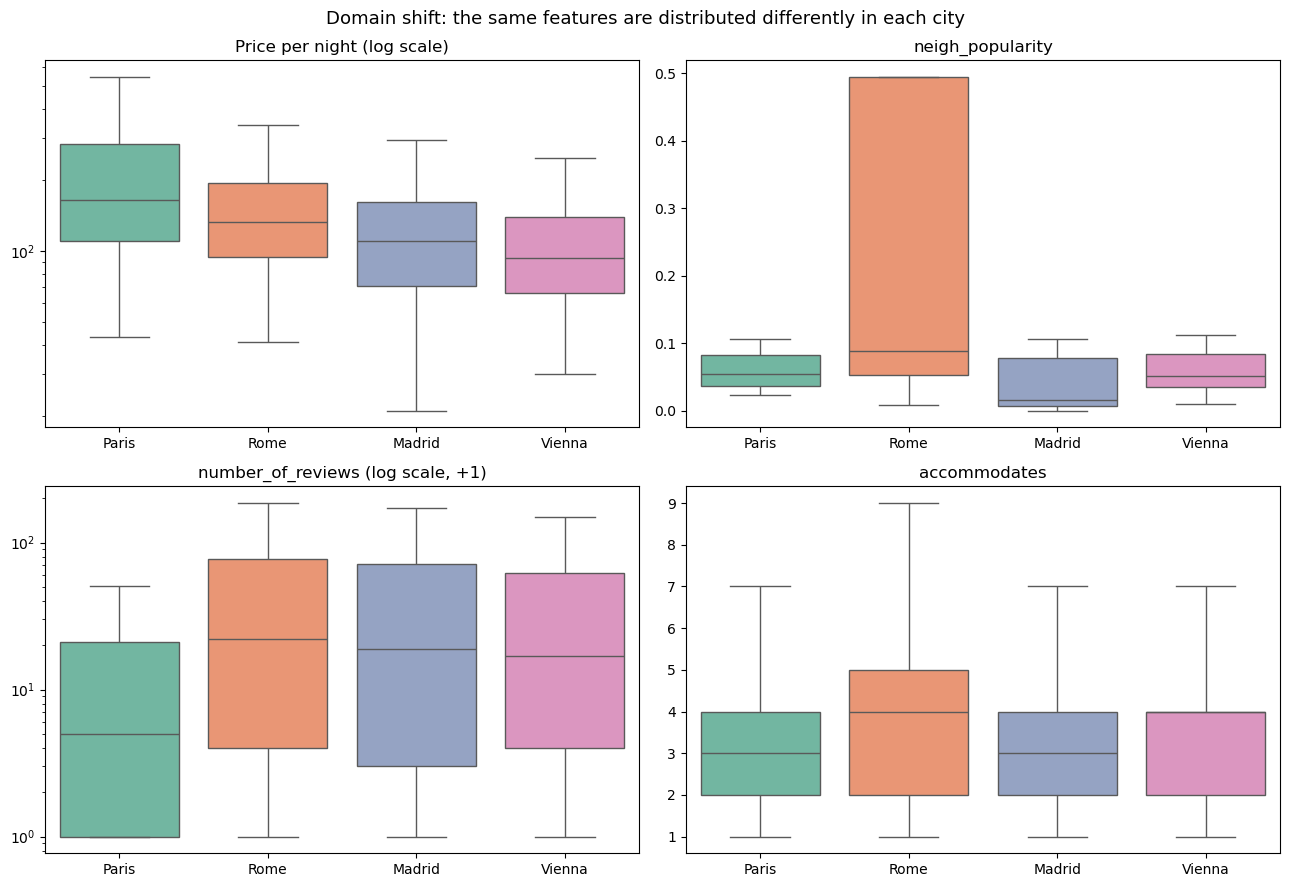

In [3]:
df_all4 = pd.concat([df_train_global, df_vienna], ignore_index=True)

summary_city = df_all4.groupby('city_label').agg(
    listings=('price_clean', 'size'),
    price_Q1=('price_clean', lambda s: s.quantile(0.25)),
    price_median=('price_clean', 'median'),
    price_Q3=('price_clean', lambda s: s.quantile(0.75)),
    entire_home_share=('rt_Entire home/apt', 'mean'),
    neigh_popularity_median=('neigh_popularity', 'median'),
    reviews_median=('number_of_reviews', 'median'),
    min_nights_median=('minimum_nights_avg_ntm', 'median'),
).loc[CITIES]
print(summary_city.round(3).to_string())

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
panels = [('price_clean', 'Price per night (log scale)', True),
          ('neigh_popularity', 'neigh_popularity', False),
          ('number_of_reviews', 'number_of_reviews (log scale, +1)', True),
          ('accommodates', 'accommodates', False)]
for ax, (col, title, log) in zip(axes.ravel(), panels):
    values = df_all4[col] + (1 if col == 'number_of_reviews' else 0)
    sns.boxplot(x=df_all4['city_label'], y=values, order=CITIES, ax=ax, showfliers=False,
                hue=df_all4['city_label'], palette='Set2', legend=False)
    if log:
        ax.set_yscale('log')
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.suptitle('Domain shift: the same features are distributed differently in each city', fontsize=13)
plt.tight_layout()
save_fig("dg_01_domain_shift_features")
plt.show()

**Reading the table and the plots.**
* Price level: the Paris quartile boundaries (110 / 164 / 284) are far above Vienna's (66 / 93 / 139). A Vienna listing at the start of its top quartile (about 140) would be in the bottom half in Paris.
* `neigh_popularity`: its median is 0.016 in Madrid (128 small *barrios*) against 0.05–0.09 elsewhere. In Rome, the central *Municipio I* holds about half of all listings, so `neigh_popularity` is close to a "historic centre" indicator there.
* Reviews: the median Paris listing has only 4 reviews (34% have none), against 16–21 in the other cities (13–16% without reviews). This is consistent with many recently created listings in the June 2024 Paris scrape, made just before the Olympic Games.
* Listing type: 91% of Paris listings are entire homes, against 73% in Madrid.

A simple way to measure covariate shift is to train a classifier to recognise the **city** from the 27 features. If it succeeds, the cities occupy different regions of the feature space, and a price model can learn city-specific rules that will not transfer.

City recognised from the raw features: balanced accuracy = 0.838 (chance = 0.25)


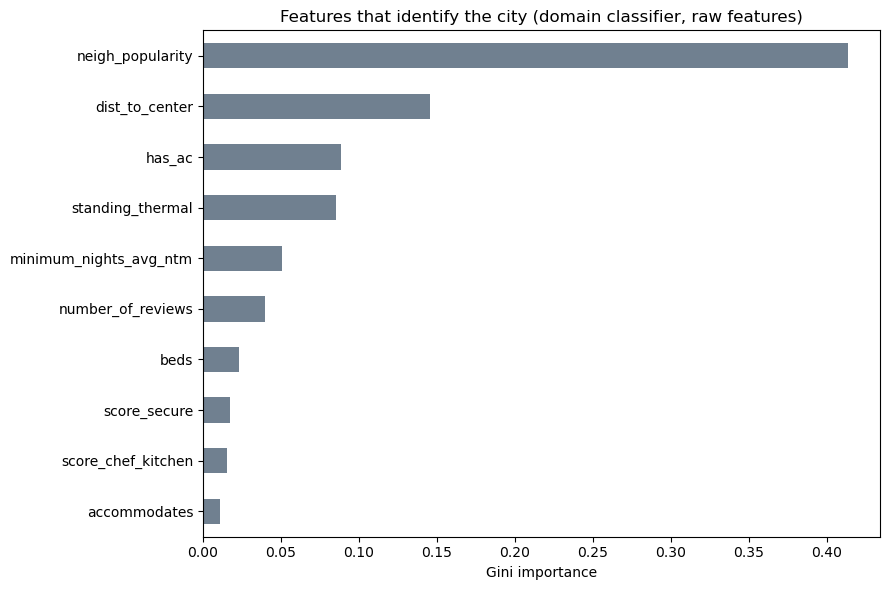

In [4]:
dom_cv = StratifiedKFold(3, shuffle=True, random_state=42)
dom_rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1)
dom_X, dom_y = df_all4.drop(columns=DROP), df_all4['city_label']

dom_pred = cross_val_predict(dom_rf, dom_X, dom_y, cv=dom_cv)
print(f"City recognised from the raw features: balanced accuracy = {balanced_accuracy_score(dom_y, dom_pred):.3f} (chance = 0.25)")

dom_rf.fit(dom_X, dom_y)
dom_imp = pd.Series(dom_rf.feature_importances_, index=dom_X.columns).sort_values()
plt.figure(figsize=(9, 6))
dom_imp.tail(10).plot(kind='barh', color='slategray')
plt.title('Features that identify the city (domain classifier, raw features)')
plt.xlabel('Gini importance')
plt.tight_layout()
save_fig("dg_02_domain_classifier_importance")
plt.show()

The city is recognised with a balanced accuracy of about 0.84 (chance = 0.25), so the shift between cities is strong. `neigh_popularity` alone carries 40% of the domain classifier's importance, followed by the distance to the centre and air-conditioning (`has_ac`: 77% of listings in Rome and 69% in Madrid, against 15% in Paris and 22% in Vienna).

We do not repeat this test on the per-city standardised features: once standardised, integer features such as `accommodates` take values specific to each city (e.g. (2 − mean)/std differs by city), and a tree recognises the city from these exact values. The test would then measure that artefact rather than the alignment of the distributions.

Random forest model trained on Paris, Rome and Madrid data (features standardised per city), then tested on Vienna.

We apply cross-stratification on city and price quantile to make sure classes are balanced across splits. This stratification is also used to reduce the dataset size before running the grid search.

In [5]:
stratify_key = df_train_global['city_label'].astype(str) + "_" + df_train_global['target_class'].astype(str)

print("Distribution of the 12 subgroups before sampling:")
print(stratify_key.value_counts(normalize=True).head())

Distribution of the 12 subgroups before sampling:
Paris_0    0.153384
Paris_2    0.146844
Paris_3    0.146443
Paris_1    0.140023
Rome_1     0.066846
Name: proportion, dtype: float64


In [6]:
df_search, _ = train_test_split(
    df_train_std, 
    train_size=0.25,     # keep 25% for the Grid Search (around 30k rows)
    stratify=stratify_key,   
    random_state=123
)

In [7]:
# Split into X (features) and y (target)
y_search = df_search['target_class']
X_search = df_search.drop(columns=['target_class', 'price_clean', 'city_label'])  
# also drop 'price_clean': the target is derived from it

print(f"\nFeatures (X) : {X_search.shape[1]} columns")
print(f"Target (y) : {len(y_search)} values")
print(f"\nClass distribution:")
print(y_search.value_counts().sort_index())

# For the final training run
X_train_full = df_train_std.drop(columns=['target_class', 'price_clean', 'city_label'])
y_train_full = df_train_global['target_class']

print(f"Shape of X_search (Grid Search) : {X_search.shape}")
print(f" Shape of X_train_full (Final) : {X_train_full.shape}")


Features (X) : 27 columns
Target (y) : 31153 values

Class distribution:
target_class
0    8025
1    7612
2    7740
3    7776
Name: count, dtype: int64
Shape of X_search (Grid Search) : (31153, 27)
 Shape of X_train_full (Final) : (124615, 27)


In [8]:
# Check that stratification worked as expected
print("Checking distribution of Paris_0:")
prop_full = (stratify_key == "Paris_0").mean()
prop_search = ((df_search['city_label'] == 'Paris') & (df_search['target_class'] == 0)).mean()
print(f"   In the full 125k rows : {prop_full*100:.2f}%")
print(f"   In the 25k subsample  : {prop_search*100:.2f}%")

Checking distribution of Paris_0:
   In the full 125k rows : 15.34%
   In the 25k subsample  : 15.34%


Grid search to find the best hyperparameters using cross-validation.

Limitation: the 3 folds mix listings of the three source cities, so this CV selects the configuration that is best *in-distribution*, not necessarily the one that transfers best to a new city. A grid search scored with leave-one-city-out folds would be the strict choice (see the extensions).

In [9]:
param_grid = {
# Deeper trees since the data is more "complex"
    'max_depth': [15, 20, 25, None],
    # Forcing leaves to contain more samples helps the model group listings
    # from different cities together, pushing it to find cross-city patterns
    # rather than city-specific ones.
    'min_samples_leaf': [2, 5, 10],  
    # Minimum number of samples required to split a node
    'min_samples_split': [5, 10, 20],
    'n_estimators': [200, 300],
    # Keeping this fixed to limit computation time
    'max_features': ['sqrt']
}

In [10]:
print(y_search.value_counts(normalize=True))

target_class
0    0.257600
3    0.249607
2    0.248451
1    0.244342
Name: proportion, dtype: float64


In [11]:
def run_domain_generalization_grid_search(X, y, param_grid, cv_folds=3, scoring_metric='f1_macro'):
    print(f"Multi-domain Grid Search (metric: {scoring_metric}, CV: {cv_folds})")
    
    rf = RandomForestClassifier(random_state=42, n_jobs=-1)
    
    grid_search = GridSearchCV(
        estimator=rf,
        param_grid=param_grid,
        cv=cv_folds,             # 3-Fold Cross Validation
        scoring=scoring_metric,
        return_train_score=True, 
        n_jobs=-1,
        verbose=1
    )
    
    # Train on the stratified subsample
    grid_search.fit(X, y)
    
    results = pd.DataFrame(grid_search.cv_results_)
    
    cols_interest = [
        'param_max_depth', 
        'param_max_features', 
        'param_min_samples_leaf', 
        'param_min_samples_split', 
        'param_n_estimators',
        'mean_test_score',        
        'std_test_score',          # variance across folds
        'mean_train_score'         
    ]
    summary = results[cols_interest].copy()
    
    summary.rename(columns={
        'mean_test_score': 'Mean_CV_Score',
        'std_test_score': 'CV_Std (Variance)',
        'mean_train_score': 'Train_Score (Overfit?)'
    }, inplace=True)
    
    summary = summary.sort_values(by='Mean_CV_Score', ascending=False)
    
    return grid_search.best_estimator_, summary

In [12]:
# takes between 4 and 10 mins: results are cached in results/ and only recomputed when the cache is missing
GRID_CACHE_DG = RESULTS_DIR / "rf_grid_dg_f1_macro.csv"
RUN_GRID_SEARCH = not GRID_CACHE_DG.exists()
if RUN_GRID_SEARCH:
    best_model_dg, res_dg = run_domain_generalization_grid_search(
    X_search,
    y_search,
    param_grid=param_grid,
    cv_folds=3,
    scoring_metric='f1_macro'
    )
    res_dg.to_csv(GRID_CACHE_DG, index=False)
else:
    res_dg = pd.read_csv(GRID_CACHE_DG)

print("Top 5 configurations (domain generalization - F1-macro):")
print(res_dg.head(5).to_string(index=False))

Multi-domain Grid Search (metric: f1_macro, CV: 3)
Fitting 3 folds for each of 72 candidates, totalling 216 fits


Top 5 configurations (domain generalization - F1-macro):
param_max_depth param_max_features  param_min_samples_leaf  param_min_samples_split  param_n_estimators  Mean_CV_Score  CV_Std (Variance)  Train_Score (Overfit?)
             20               sqrt                       2                        5                 300       0.549934           0.003962                0.928803
             20               sqrt                       2                        5                 200       0.549040           0.003794                0.927251
             25               sqrt                       2                        5                 300       0.548830           0.002576                0.946461
             25               sqrt                       2                       10                 300       0.548689           0.003588                0.870971
           None               sqrt                       2                       10                 300       0.548659           0.00

In [13]:
# best configuration of the grid search, used for the final model and for the LODO evaluation
best_cfg = res_dg.iloc[0]
best_params_dg = {
    'max_depth': None if pd.isna(best_cfg['param_max_depth']) else int(best_cfg['param_max_depth']),
    'max_features': best_cfg['param_max_features'],
    'min_samples_leaf': int(best_cfg['param_min_samples_leaf']),
    'min_samples_split': int(best_cfg['param_min_samples_split']),
    'n_estimators': int(best_cfg['param_n_estimators'])
}
print(best_params_dg)

{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 300}


Training on (124615, 27)


OOB Score: 0.5849
               Feature  Importance
        dist_to_center    0.149657
     number_of_reviews    0.087968
          accommodates    0.084899
minimum_nights_avg_ntm    0.082617
      neigh_popularity    0.081068
              bedrooms    0.072296
         bathrooms_qty    0.056927
                  beds    0.046980
    score_chef_kitchen    0.042206
          score_secure    0.028480


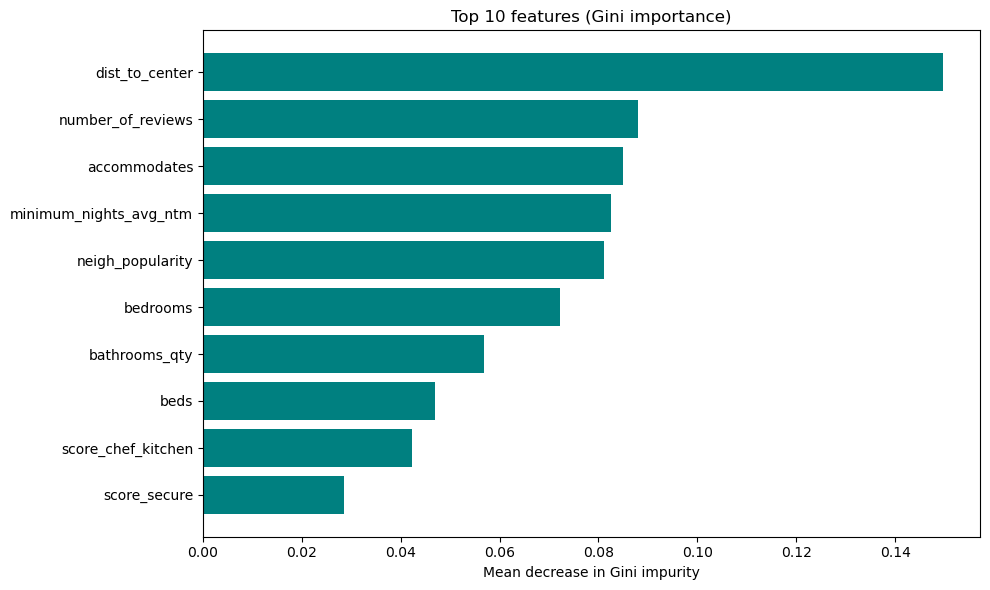

In [14]:
final_rf = RandomForestClassifier(
    **best_params_dg,
    oob_score=True,       # in-distribution estimate (the OOB rows come from the same 3 cities)
    random_state=123,
    n_jobs=-1
)
# Domain weighting: prevents Paris (73k rows) from overwhelming Rome (33k) and Madrid (19k)
# compute_sample_weight assigns weights inversely proportional to domain size
domain_weights = compute_sample_weight(
    class_weight='balanced',
    y=df_train_global['city_label']
)
# Train on the full dataset
print(f"Training on {X_train_full.shape}")

final_rf.fit(X_train_full, y_train_full, sample_weight=domain_weights)

print(f"OOB Score: {final_rf.oob_score_:.4f}")

# Feature importances
feature_importances = pd.DataFrame({
    'Feature': X_train_full.columns,
    'Importance': final_rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(feature_importances.head(10).to_string(index=False))

plt.figure(figsize=(10, 6))
plt.barh(feature_importances['Feature'][:10][::-1], feature_importances['Importance'][:10][::-1], color='teal')
plt.title("Top 10 features (Gini importance)")
plt.xlabel("Mean decrease in Gini impurity")
plt.tight_layout()
save_fig("dg_03_final_model_gini_importance")
plt.show()

The OOB score (≈ 0.58) is an in-distribution estimate: the out-of-bag listings come from the same three cities as the training data. It says nothing about the score on Vienna, which is measured below. The Gini importances favour continuous features with many split points (distance, review counts, minimum nights), so they are not read as causal effects.

In [15]:
def rerank_predictions(y_proba):
    """
    Takes model probabilities (N, 4) and forces a balanced distribution
    across 4 quartiles (25% each) based on the expected class value.
    Needs the whole batch of listings of the target city at once.
    """
    # Compute expected class value (continuous score from 0 to 3)
    classes = np.array([0, 1, 2, 3])
    expected_scores = np.dot(y_proba, classes)
    
    # Rank all listings; 'first' breaks ties by order of appearance
    ranks = pd.Series(expected_scores).rank(method='first')
    
    # Cut into 4 strict quartiles
    y_pred_reranked = pd.qcut(ranks, q=4, labels=[0, 1, 2, 3]).astype(int)
    
    return y_pred_reranked.values

Without reranking (F1-Macro): 0.46118409858880804
With reranking (F1-Macro): 0.4633335174721972

Classification report (with reranking):
              precision    recall  f1-score   support

           0       0.57      0.56      0.56      2575
           1       0.35      0.34      0.34      2562
           2       0.35      0.35      0.35      2486
           3       0.59      0.60      0.60      2492

    accuracy                           0.46     10115
   macro avg       0.46      0.46      0.46     10115
weighted avg       0.46      0.46      0.46     10115

   True classes  Raw predict()  Reranked
0         0.255          0.273      0.25
1         0.253          0.305      0.25
2         0.246          0.224      0.25
3         0.246          0.198      0.25


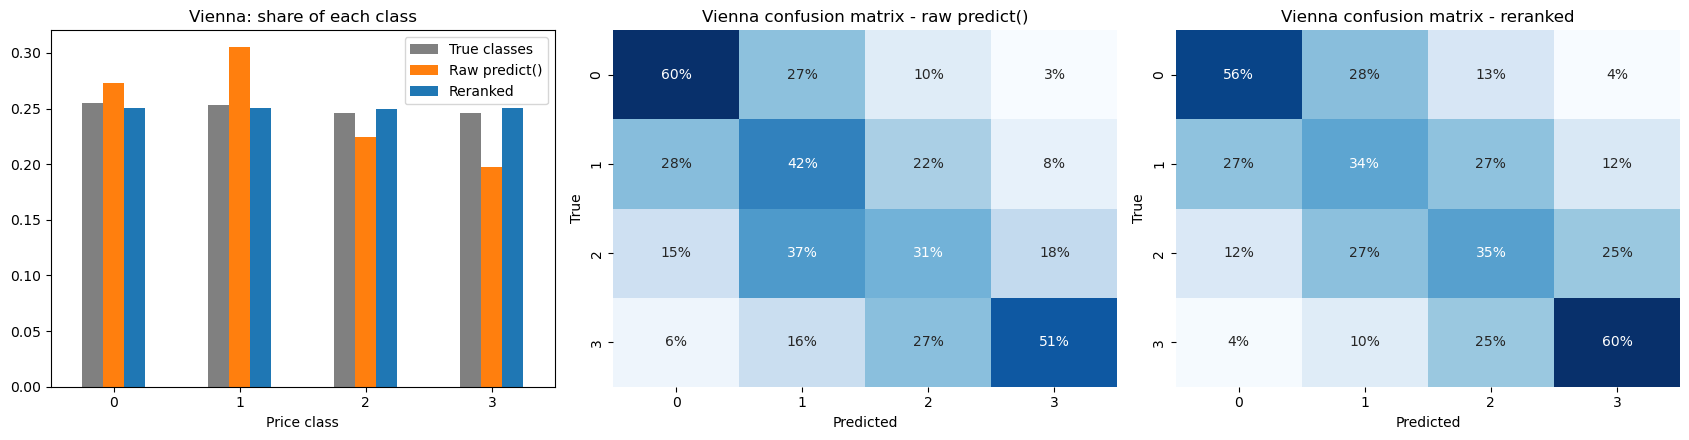

In [16]:
X_test_vienna, y_test_vienna = df_vienna_std.drop(columns=['target_class', 'price_clean', 'city_label']), df_vienna_std['target_class']

# Direct prediction
y_pred_vienna = final_rf.predict(X_test_vienna)

# Prediction with reranking
y_proba_vienna = final_rf.predict_proba(X_test_vienna)
y_pred_reranked_vienna = rerank_predictions(y_proba_vienna)

print("Without reranking (F1-Macro):", f1_score(y_test_vienna, y_pred_vienna, average='macro'))
print("With reranking (F1-Macro):", f1_score(y_test_vienna, y_pred_reranked_vienna, average='macro'))

print("\nClassification report (with reranking):")
print(classification_report(y_test_vienna, y_pred_reranked_vienna))

# Share of each predicted class: the true classes are quartiles (~25% each)
shares = pd.DataFrame({
    'True classes': pd.Series(y_test_vienna).value_counts(normalize=True),
    'Raw predict()': pd.Series(y_pred_vienna).value_counts(normalize=True),
    'Reranked': pd.Series(y_pred_reranked_vienna).value_counts(normalize=True),
}).sort_index().fillna(0)
print(shares.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
shares.plot(kind='bar', ax=axes[0], rot=0, color=['grey', 'tab:orange', 'tab:blue'])
axes[0].set_title('Vienna: share of each class')
axes[0].set_xlabel('Price class')
for ax, pred, title in [(axes[1], y_pred_vienna, 'raw predict()'), (axes[2], y_pred_reranked_vienna, 'reranked')]:
    cm = confusion_matrix(y_test_vienna, pred, normalize='true')
    sns.heatmap(cm, annot=True, fmt='.0%', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'Vienna confusion matrix - {title}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.tight_layout()
save_fig("dg_04_vienna_raw_vs_reranked")
plt.show()

On Vienna the raw `predict()` over-predicts the "Standard" class (31% of predictions) and under-predicts "Luxury" (20%), although each class holds about 25% of the listings. Reranking restores the 25% shares, but the F1-macro barely moves (0.461 → 0.463): with per-city standardisation the raw predictions are already less biased than with raw features. As in Paris, the extreme classes are recognised much better (F1 ≈ 0.56–0.60) than the two middle ones (≈ 0.35).

Leave-One-City-Out: train on 3 cities, test on the 4th — a clean way to evaluate domain generalization, since every city is used once as an unseen target.

In [17]:
def run_lodo(df_all_cities, best_params, domain_weighting=True, per_city_std=True, verbose=True):
    """Leave-one-city-out: train on 3 cities, test on the 4th, with raw (argmax) and reranked predictions."""
    data = standardize_per_city(df_all_cities) if per_city_std else df_all_cities
    results = []

    for test_city in CITIES:
        # Train/test split by domain
        df_train = data[data['city_label'] != test_city]
        df_test  = data[data['city_label'] == test_city]

        # Drop price_clean: the target is derived from it
        X_train = df_train.drop(columns=DROP)
        y_train = df_train[TARGET]
        X_test = df_test.drop(columns=DROP)
        y_test = df_test[TARGET].values

        # Domain weighting
        weights = compute_sample_weight(class_weight='balanced', y=df_train['city_label']) if domain_weighting else None

        rf = RandomForestClassifier(**best_params, random_state=42, n_jobs=-1)
        rf.fit(X_train, y_train, sample_weight=weights)

        # Raw prediction and reranking
        y_proba = rf.predict_proba(X_test)
        y_pred_raw = rf.classes_[y_proba.argmax(axis=1)]
        y_pred_reranked = rerank_predictions(y_proba)

        # McNemar test on this city: does reranking change the error rate?
        ok_raw, ok_rr = (y_pred_raw == y_test), (y_pred_reranked == y_test)
        table = [[np.sum(~ok_raw & ~ok_rr), np.sum(~ok_raw & ok_rr)],
                 [np.sum(ok_raw & ~ok_rr), np.sum(ok_raw & ok_rr)]]

        results.append({
            'Target_City (Test)': test_city,
            'Source_Cities (Train)': ", ".join(c for c in CITIES if c != test_city),
            'F1_Macro_Raw': f1_score(y_test, y_pred_raw, average='macro'),
            'F1_Macro_Reranked': f1_score(y_test, y_pred_reranked, average='macro'),
            'Accuracy_Raw': accuracy_score(y_test, y_pred_raw),
            'Accuracy_Reranked': accuracy_score(y_test, y_pred_reranked),
            'McNemar_p': mcnemar(table).pvalue,
        })
        if verbose:
            r = results[-1]
            print(f"{test_city:<7} train={len(df_train):>6} test={len(df_test):>6} | F1 raw {r['F1_Macro_Raw']:.4f} "
                  f"-> reranked {r['F1_Macro_Reranked']:.4f} ({(r['F1_Macro_Reranked'] - r['F1_Macro_Raw']) * 100:+.2f} pts)")

    df_results = pd.DataFrame(results)
    df_results.loc['Global Average'] = ["-", "-"] + df_results.iloc[:, 2:6].mean().tolist() + [np.nan]
    return df_results

In [18]:
df_all_cities = pd.concat([df_train_global, df_vienna], ignore_index=True)

print("LODO cross-validation of the final pipeline (domain weighting + per-city standardisation)")
tableau_final_lodo = run_lodo(df_all_cities, best_params_dg)
display(tableau_final_lodo)

LODO cross-validation of the final pipeline (domain weighting + per-city standardisation)


Paris   train= 61619 test= 73111 | F1 raw 0.4473 -> reranked 0.4536 (+0.63 pts)


Rome    train=101828 test= 32902 | F1 raw 0.4331 -> reranked 0.4449 (+1.18 pts)


Madrid  train=116128 test= 18602 | F1 raw 0.4954 -> reranked 0.5352 (+3.98 pts)


Vienna  train=124615 test= 10115 | F1 raw 0.4671 -> reranked 0.4640 (-0.31 pts)


,Target_City (Test),Source_Cities (Train),F1_Macro_Raw,F1_Macro_Reranked,Accuracy_Raw,Accuracy_Reranked,McNemar_p
0,Paris,"Rome, Madrid, Vienna",0.447322,0.453598,0.446909,0.454802,8.492667e-09
1,Rome,"Paris, Madrid, Vienna",0.433100,0.444928,0.432679,0.445019,8.514151e-10
2,Madrid,"Paris, Rome, Vienna",0.495408,0.535215,0.524890,0.535641,4.571678e-04
3,Vienna,"Paris, Rome, Madrid",0.467127,0.464019,0.465546,0.464063,7.425923e-01
Global Average,-,-,0.460739,0.474440,0.467506,0.474881,NaN


### Ablation: what does each ingredient bring?

The LODO protocol is repeated with the same forest while adding the ingredients one at a time. Two references frame the results:
* **Naive local model**: a forest trained on Paris only and applied to the other cities (the approach of notebook 1).
* **In-domain upper bound**: 5-fold cross-validation inside each city, i.e. the score reachable when labelled listings of the target city are available.

In [19]:
# Takes ~5 min
settings = {
    'Pooled, raw features': dict(domain_weighting=False, per_city_std=False),
    '+ domain weighting': dict(domain_weighting=True, per_city_std=False),
}
ablation = {name: run_lodo(df_all_cities, best_params_dg, verbose=False, **opts) for name, opts in settings.items()}
ablation['+ per-city standardisation (final)'] = tableau_final_lodo

rows = []
for name, res in ablation.items():
    for _, r in res.drop(index='Global Average').iterrows():
        rows.append({'Setting': name, 'City': r['Target_City (Test)'],
                     'F1 raw': r['F1_Macro_Raw'], 'F1 reranked': r['F1_Macro_Reranked']})

# Naive local model: trained on Paris only (raw features, no reranking needed to define it)
paris = df_all_cities[df_all_cities['city_label'] == 'Paris']
rf_paris = RandomForestClassifier(**best_params_dg, random_state=42, n_jobs=-1).fit(paris.drop(columns=DROP), paris[TARGET])
for city in CITIES[1:]:
    d = df_all_cities[df_all_cities['city_label'] == city]
    proba = rf_paris.predict_proba(d.drop(columns=DROP))
    rows.append({'Setting': 'Paris only (naive)', 'City': city,
                 'F1 raw': f1_score(d[TARGET], rf_paris.classes_[proba.argmax(axis=1)], average='macro'),
                 'F1 reranked': f1_score(d[TARGET], rerank_predictions(proba), average='macro')})

# In-domain upper bound: 5-fold CV inside each city
for city in CITIES:
    d = df_all_cities[df_all_cities['city_label'] == city]
    pred = cross_val_predict(RandomForestClassifier(**best_params_dg, random_state=42, n_jobs=-1),
                             d.drop(columns=DROP), d[TARGET], cv=StratifiedKFold(5, shuffle=True, random_state=42))
    rows.append({'Setting': 'In-domain CV (upper bound)', 'City': city,
                 'F1 raw': f1_score(d[TARGET], pred, average='macro'), 'F1 reranked': np.nan})

ablation_long = pd.DataFrame(rows)
ablation_long.to_csv(RESULTS_DIR / "dg_ablation.csv", index=False)
order = ['Paris only (naive)', 'Pooled, raw features', '+ domain weighting',
         '+ per-city standardisation (final)', 'In-domain CV (upper bound)']
ablation_table = ablation_long.pivot_table(index='Setting', columns='City', values=['F1 raw', 'F1 reranked'])
ablation_table = ablation_table.reindex(order).reindex(columns=CITIES, level=1)
ablation_table[('F1 raw', 'Mean')] = ablation_table['F1 raw'].mean(axis=1)
ablation_table[('F1 reranked', 'Mean')] = ablation_table['F1 reranked'].mean(axis=1)
display(ablation_table.round(3))

F1 raw                      F1 reranked  \
City                                Paris   Rome Madrid Vienna       Paris   
Setting                                                                      
Paris only (naive)                    NaN  0.375  0.477  0.439         NaN   
Pooled, raw features                0.408  0.389  0.456  0.437       0.446   
+ domain weighting                  0.430  0.384  0.448  0.428       0.454   
+ per-city standardisation (final)  0.447  0.433  0.495  0.467       0.454   
In-domain CV (upper bound)          0.554  0.582  0.680  0.619         NaN   

                                                        F1 raw F1 reranked  
City                                 Rome Madrid Vienna   Mean        Mean  
Setting                                                                     
Paris only (naive)                  0.390  0.507  0.435  0.430       0.444  
Pooled, raw features                0.425  0.505  0.463  0.423       0.460  
+ domain weighting                  0.426  0.506  0.462  0.423       0.462  
+ per-city standardisation (final)  0.445  0.535  0.464  0.461       0.474  
In-domain CV (upper bound)            NaN    NaN    NaN  0.609         NaN

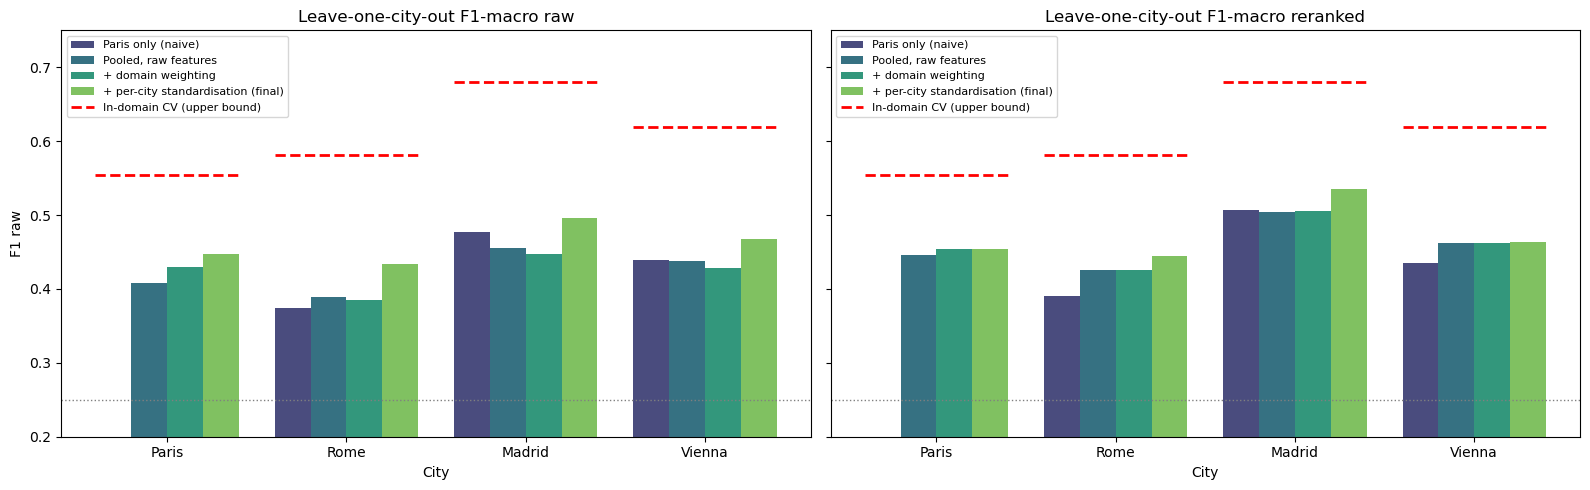

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
plot_order = order[:-1]
for ax, metric in zip(axes, ['F1 raw', 'F1 reranked']):
    sub = ablation_long[ablation_long['Setting'].isin(plot_order)]
    sns.barplot(data=sub, x='City', y=metric, hue='Setting', hue_order=plot_order, order=CITIES, ax=ax, palette='viridis')
    upper = ablation_long[ablation_long['Setting'] == 'In-domain CV (upper bound)'].set_index('City')['F1 raw']
    for k, city in enumerate(CITIES):
        ax.hlines(upper[city], k - 0.4, k + 0.4, color='red', linestyle='--', lw=2,
                  label='In-domain CV (upper bound)' if k == 0 else None)
    ax.axhline(0.25, color='grey', lw=1, linestyle=':')
    ax.set_title(f'Leave-one-city-out {metric.replace("F1", "F1-macro")}')
    ax.set_ylim(0.2, 0.75)
    ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
save_fig("dg_05_ablation_f1_by_city")
plt.show()

**Reading the ablation** (mean F1-macro over the four LODO folds, raw → reranked):

| Setting | Mean F1 raw | Mean F1 reranked |
|---|---|---|
| Paris only (naive, 3 target cities) | 0.430 | 0.444 |
| Pooled, raw features | 0.423 | 0.460 |
| + domain weighting | 0.423 | 0.462 |
| + per-city standardisation (final) | **0.461** | **0.474** |
| In-domain CV (upper bound) | 0.609 | – |

* **Per-city standardisation is the ingredient that helps most**: +3.8 points of raw F1 and +1.2 after reranking, with gains on all four cities.
* **Domain weighting has no measurable effect on average** (+2 points on Paris, −0.5 to −1 point elsewhere).
* **Reranking** adds +3.7 points to the pooled raw-feature model but only +1.4 to the final pipeline: both corrections target the same problem, a prediction that is not relative to the target city.
* **The domain gap stays large**: about 13 points between the final pipeline (0.474) and the in-domain upper bound (0.609).
* Seed changes move these scores by about ±0.5 point (compare Vienna in the LODO table, 0.467, with the final model above, 0.461), so differences below ~1 point are not meaningful.

### Do the important variables stay the same across cities?

One forest per city (80/20 split inside the city), with permutation importance measured on the held-out 20%.

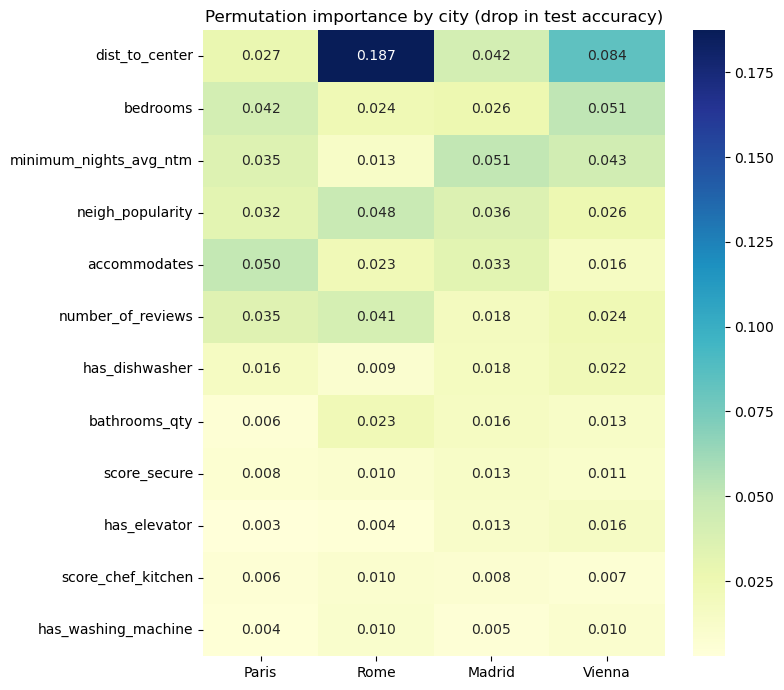

Rank of each feature within each city:
                        Paris  Rome  Madrid  Vienna
dist_to_center              6     1       2       1
bedrooms                    2     4       5       2
minimum_nights_avg_ntm      3     7       1       3
neigh_popularity            5     2       3       4
accommodates                1     5       4       7
number_of_reviews           4     3       6       5
has_dishwasher              7    11       7       6
bathrooms_qty              10     6       8       9
score_secure                8    10       9      10
has_elevator               15    15      10       8
score_chef_kitchen          9     9      13      15
has_washing_machine        11     8      17      11


In [21]:
# Takes ~2 min
imp_by_city = {}
for city in CITIES:
    d = df_all_cities[df_all_cities['city_label'] == city]
    X_tr, X_te, y_tr, y_te = train_test_split(d.drop(columns=DROP), d[TARGET], test_size=0.2,
                                              stratify=d[TARGET], random_state=42)
    rf_city = RandomForestClassifier(**best_params_dg, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
    imp_by_city[city] = permutation_importance(rf_city, X_te, y_te, n_repeats=3, random_state=42).importances_mean
imp_by_city = pd.DataFrame(imp_by_city, index=X_tr.columns)
top_features = imp_by_city.mean(axis=1).sort_values(ascending=False).index[:12]

plt.figure(figsize=(8, 7))
sns.heatmap(imp_by_city.loc[top_features], annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('Permutation importance by city (drop in test accuracy)')
plt.tight_layout()
save_fig("dg_06_permutation_importance_by_city")
plt.show()
print("Rank of each feature within each city:")
print(imp_by_city.rank(ascending=False).loc[top_features].astype(int))

The drivers of the price class change from one city to another. The distance to the centre dominates in Rome (0.19 drop in accuracy, far above any other feature) and ranks first in Vienna, but only sixth in Paris, where capacity (`accommodates`, `bedrooms`) comes first. Minimum stay is the top feature in Madrid. A single set of rules learned on some cities therefore cannot fit all of them, which explains a large part of the domain gap.

### Conclusion

**What the experiments show**
1. **The domain gap is large.** Inside a city, the forest reaches an F1-macro of 0.55–0.68 (mean 0.61). On a city it has never seen, the best pipeline reaches 0.45–0.54 (mean 0.47). About 13 points are lost because the rules learned elsewhere only partly transfer (see the per-city importances).
2. **A naive local model does not "completely fail", but it is the weakest option.** Trained on Paris only, it scores 0.43 on average on Rome, Madrid and Vienna (chance = 0.25), against 0.465 for the final pipeline on the same three cities (0.444 vs 0.481 after reranking).
3. **Per-city standardisation helps most** (+3.8 points of raw F1). Because the target is a within-city quartile, the model must rank listings relative to their own city; expressing the features relative to the city as well removes city-specific scales, such as `neigh_popularity`, whose scale depends on how the city is divided into neighbourhoods.
4. **Domain weighting has no measurable effect.** Giving each city the same weight is not enough to make the forest learn city-invariant rules.
5. **Reranking** helps when the raw predictions are biased: +3.7 points on the pooled raw-feature model, +1.4 on the final pipeline. The gain is significant (McNemar) for Paris, Rome and Madrid, not for Vienna.

### Why reranking can work
By construction, each price class holds 25% of the listings of a city. `predict()` takes the most probable class of each listing (maximum a posteriori). This is optimal for accuracy only if the predicted probabilities are calibrated for the target city; under domain shift they are not, and the predicted class shares drift (on Vienna: 27 / 31 / 22 / 20%). The reranker:
* summarises each listing by its **expected class** $E[Y|X] = \sum_y y \cdot P(Y=y|X)$, which keeps the ordinal information (a listing torn between classes 2 and 3 is placed between them) and minimises the expected squared error on the class index;
* ranks these scores and cuts them into four equal groups, so the predicted shares match the known **25% prior**. This is a form of label-shift correction.

Its limits: it needs the whole batch of listings of the new city at once, and it relies on the classes being quartiles of that city's own prices — in practice, the price distribution of the new city must be known to define the target.

### Limits of the study
* One random-forest configuration, tuned with a CV that mixes the source cities (in-distribution selection).
* Four cities only, and Paris was scraped at a different date (June 2024, just before the Olympics) from the others (September 2025): the time shift is mixed with the city shift.
* The features miss strong price drivers (surface area, photos, review scores, exact location quality), which caps even the in-domain score at about 0.6.

To check that the reranking gain is not noise, we close with a **McNemar test** on Vienna and on every LODO fold.

In [22]:
from statsmodels.stats.contingency_tables import mcnemar
# We used a coding agent to help implementing the test with statsmodels
print("Null Hypothesis (H0): The raw model and the reranked model have the same error rate.")
print("Alternative Hypothesis (H1): Reranking significantly changes model performance.\n")

# Boolean vectors, testing on the first model (Vienna)
correct_raw = (y_pred_vienna == y_test_vienna)
correct_reranked = (y_pred_reranked_vienna == y_test_vienna)

# Build the McNemar contingency table
# Only the cases where the two models disagree matter
table = [
    [sum(~correct_raw & ~correct_reranked), sum(~correct_raw & correct_reranked)],
    [sum(correct_raw & ~correct_reranked),  sum(correct_raw & correct_reranked)]
]

print("Contingency table (disagreements):")
print(f"Raw was wrong, reranking fixed it: {table[0][1]} listings")
print(f"Raw was right, reranking broke it: {table[1][0]} listings\n")

result = mcnemar(table)

print(f"Test p-value: {result.pvalue:.5e}")

if result.pvalue < 0.05:
    print("result: H0 rejected.")
    print("Reranking changes the error rate significantly on Vienna.")
else:
    print("RESULT: Failed to reject H0.")
    print("The difference may be due to random variation on this sample.")

print("\nMcNemar p-values per LODO fold (final pipeline):")
print(tableau_final_lodo.drop(index='Global Average')[['Target_City (Test)', 'Accuracy_Raw', 'Accuracy_Reranked', 'McNemar_p']].to_string(index=False))

Null Hypothesis (H0): The raw model and the reranked model have the same error rate.
Alternative Hypothesis (H1): Reranking significantly changes model performance.

Contingency table (disagreements):
Raw was wrong, reranking fixed it: 933 listings
Raw was right, reranking broke it: 896 listings

Test p-value: 3.99921e-01
RESULT: Failed to reject H0.
The difference may be due to random variation on this sample.

McNemar p-values per LODO fold (final pipeline):
Target_City (Test)  Accuracy_Raw  Accuracy_Reranked    McNemar_p
             Paris      0.446909           0.454802 8.492667e-09
              Rome      0.432679           0.445019 8.514151e-10
            Madrid      0.524890           0.535641 4.571678e-04
            Vienna      0.465546           0.464063 7.425923e-01


On Vienna the reranking fixes about as many listings as it breaks (p ≈ 0.4), so its effect there is not significant. On Paris, Rome and Madrid the gain is small (+0.8 to +1.2 points of accuracy) but significant (p < 0.001), thanks to the large test sets. With per-city standardisation in place, reranking is a cheap, low-risk post-processing step rather than the main source of the improvement.